<a href="https://colab.research.google.com/github/drijal/BDMS_STI_2026/blob/main/notebooks/cap_gdp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone: GDP Nowcasting with Satellite Data and Machine Learning

## 1. Setup

In [13]:
from google.colab import drive
drive.mount('/content/drive')

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import pickle
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

RANDOM_STATE = 42

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Import data

In [14]:
ROOT = "/content/drive/MyDrive/BDMS_STI_2026-main/"
data_folder = "data/Capstone/Data"
data_path = os.path.join(ROOT, data_folder)
data_path

'/content/drive/MyDrive/BDMS_STI_2026-main/data/Capstone/Data'

In [15]:
# Check
os.path.exists(data_path)

True

▶ Remember you can use `BDC_Data_Extract_Satellite_Data` and `BDC_Data_Preprocessing_for_GDP_Nowcasting` to extract and process data for another country. However, data extraction may take long.

In [16]:
# Read the sample CSV file
filename = 'model_data_sample.csv'
filepath = os.path.join(data_path, filename)
df_imported = pd.read_csv(filepath)
df_imported

,index,month,diff_mean_ntl,diff_sum_ntl,diff_mean_ntl_dnb,diff_sum_ntl_dnb,diff_sum_evi,diff_mean_evi,diff_mean_ndvi,diff_sum_ndvi,...,diff_sum_pcp,diff_sum_asi,diff_mean_asi,diff_sum_ndvi_anomaly,diff_mean_ndvi_anomaly,diff_sum_vhi,diff_mean_vhi,diff_gti_tourism,year_current,GDP
0,4/1/2012,6,10.292547,10.293112,4.340000e-15,1.650000e-14,-4.649033,-4.902775,-8.794158,-8.510306,...,110.138578,-108.962638,-108.962638,12.952004,12.952004,18.178192,18.178192,-39.285714,2.012200e+11,7.7
1,7/1/2012,15,-56.139271,-56.354113,-2.673902e+01,-1.331783e+02,78.269822,78.188694,69.381350,69.513441,...,80.650365,-69.105709,-69.105709,0.761385,0.761385,6.859891,6.859891,-14.285714,2.012200e+11,7.5
2,10/1/2012,24,-34.335817,-34.183791,-2.521913e+01,-1.042377e+02,10.436676,10.483551,8.513852,8.432509,...,45.605087,-77.856364,-77.856364,9.972773,9.972773,22.912352,22.912352,3.333333,2.012200e+11,8.1
3,1/1/2013,33,-46.793983,-46.813549,-3.497977e+01,-1.196342e+02,-10.775800,-10.738883,-6.998381,-7.019063,...,127.482296,75.207061,75.207061,-12.901643,-12.901643,4.600831,4.600831,-40.000000,2.012200e+11,7.9
4,4/1/2013,6,-64.937834,-64.960939,-3.494007e+01,-1.158688e+02,18.743478,18.995127,28.203604,27.907043,...,-16.066903,898.254797,898.254797,-6.998738,-6.998738,-28.610727,-28.610727,-33.333333,2.013200e+11,7.6
5,7/1/2013,15,32.909761,32.679691,1.230583e+01,1.030715e+02,40.724507,40.497763,46.287867,46.492933,...,-1.689800,38.739364,38.739364,13.853057,13.853057,8.276475,8.276475,-16.666667,2.013200e+11,7.9
6,10/1/2013,24,18.916248,18.562763,-6.669966e-01,-4.277370e+00,0.112228,0.100233,1.889666,1.868885,...,-2.842645,195.409774,195.409774,4.144324,4.144324,-22.060224,-22.060224,-33.333333,2.013200e+11,7.7
7,1/1/2014,33,38.102972,38.103032,1.749952e+01,9.264490e+01,22.777969,22.791689,19.005991,18.955303,...,-25.821652,358.517387,358.517387,12.605514,12.605514,-21.276926,-21.276926,25.000000,2.013200e+11,7.6
8,4/1/2014,6,28.784359,28.784593,2.627797e+00,1.383874e+01,19.507325,19.382423,13.992043,14.108827,...,3.686600,-88.489854,-88.489854,31.245638,31.245638,0.389931,0.389931,-16.666667,2.014200e+11,7.7
9,7/1/2014,15,-1.444607,-1.610617,-6.488444e+00,-4.146550e+01,1.392611,1.336294,-4.702113,-4.626827,...,-0.605477,87.029340,87.029340,-12.616099,-12.616099,-10.749841,-10.749841,-28.571429,2.014200e+11,7.3


## 3. Data processing

In [17]:
df = df_imported.copy()

col = [
    'index', 'year_current', 'diff_sum_ntl', 'diff_sum_evi',
    'diff_sum_ndvi', 'diff_sum_no2', 'diff_sum_pcp', 'diff_sum_asi',
    'diff_sum_ndvi_anomaly', 'diff_sum_vhi', 'diff_gti_tourism', 'GDP'
]
df = df[col].copy()

df['year_current'] = df['year_current'].astype(str).str[:4]
df.rename(columns={'year_current': 'year'}, inplace=True)
df.columns = df.columns.str.replace('diff_sum_', '', regex=False).str.replace('diff_', '', regex=False)
df.tail()

,index,year,ntl,evi,ndvi,no2,pcp,asi,ndvi_anomaly,vhi,gti_tourism,GDP
49,7/1/2024,2024,-50.990729,71.345499,64.004773,-14.993598,108.526146,-105.245120,-6.652373,9.161975,40.000000,4.6
50,10/1/2024,2024,-126.106570,8.963546,10.301868,-11.174333,7.405165,-122.880724,-3.642977,6.258598,66.666667,5.4
51,1/1/2025,2024,-39.527111,20.579891,16.900511,-47.025161,-31.256746,-110.087006,12.318746,31.740981,96.666667,5.4
52,4/1/2025,2025,5.501643,43.953696,42.818011,69.971405,-70.904722,70.972194,6.917781,-3.803451,64.285714,5.2
53,7/1/2025,2025,115.012146,-56.360015,-50.968105,-6.494502,-37.740998,261.085872,11.862275,-15.727949,104.761905,NaN


In [18]:
feature_cols = [
    # 'year',
    'ntl', 'evi', 'ndvi', 'no2', 'pcp',
    'asi', 'ndvi_anomaly', 'vhi', 'gti_tourism'
]

# Keep the date/index column for ordering and plots, not as a model feature.
df['index'] = pd.to_datetime(df['index'])
df = df.sort_values('index').reset_index(drop=True)

known = df.dropna(subset=['GDP']).reset_index(drop=True)
to_nowcast = df[df['GDP'].isna()].reset_index(drop=True)

print('Known GDP observations:', len(known))
print('Quarters to nowcast:', len(to_nowcast))

Known GDP observations: 53
Quarters to nowcast: 1


## 4. Train and test

In [19]:
n_test = 4

train = known.iloc[:-n_test].copy()
test = known.iloc[-n_test:].copy()

train_X = train[feature_cols]
train_y = train['GDP']
test_X = test[feature_cols]
test_y = test['GDP']

print('Training observations:', len(train))
print('Test observations:', len(test))

Training observations: 49
Test observations: 4


In [20]:
model = RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE)
model.fit(train_X, train_y)
predictions = model.predict(test_X)

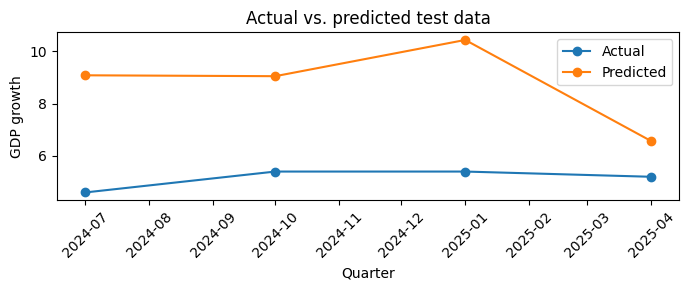

In [21]:
plt.figure(figsize=(7, 3))
plt.plot(test['index'], test_y, marker='o', label='Actual')
plt.plot(test['index'], predictions, marker='o', label='Predicted')
plt.xlabel('Quarter')
plt.ylabel('GDP growth')
plt.title('Actual vs. predicted test data')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [22]:
mse = mean_squared_error(test_y, predictions)
rmse = np.sqrt(mse)
mae = mean_absolute_error(test_y, predictions)

print('Mean Squared Error:', round(mse, 3))
print('Root Mean Squared Error:', round(rmse, 3))
print('Mean Absolute Error:', round(mae, 3))

Mean Squared Error: 15.174
Root Mean Squared Error: 3.895
Mean Absolute Error: 3.635


## 5. Model explainability

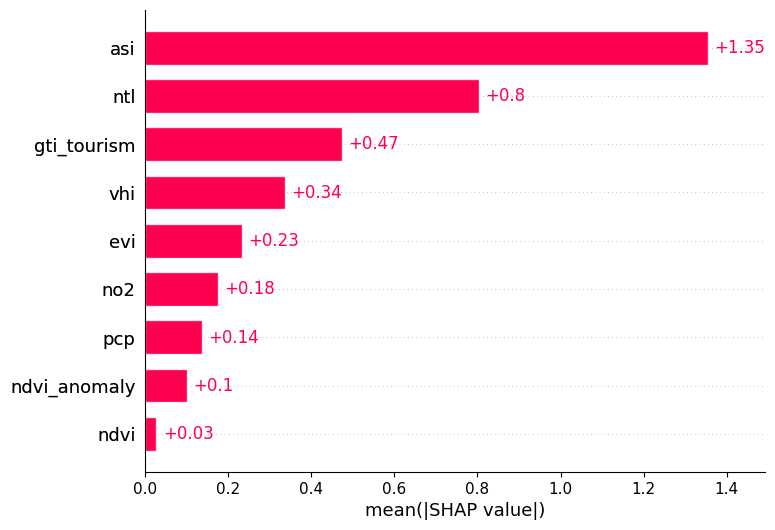

In [23]:
explainer = shap.Explainer(model, train_X)
shap_values = explainer(test_X)
shap.plots.bar(shap_values)

Quarter: 2024-07-01


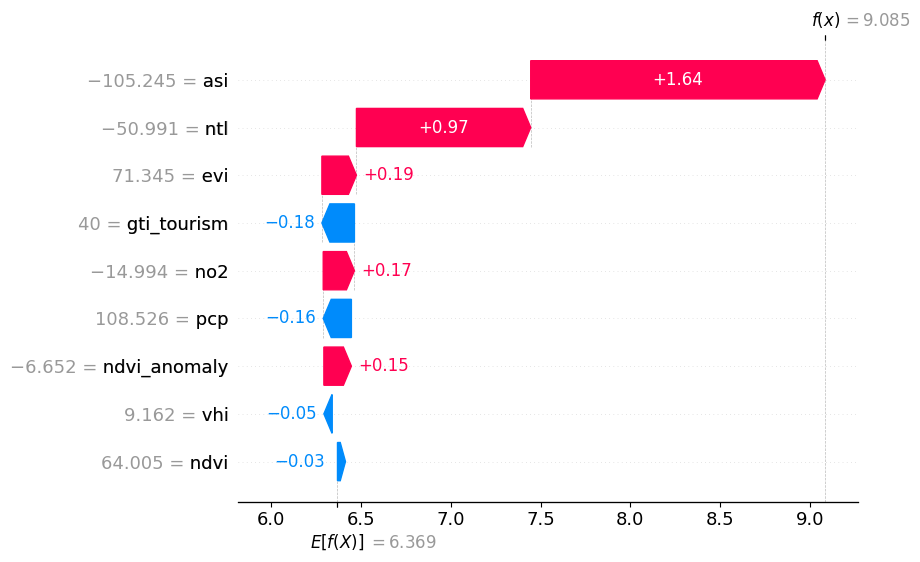

In [24]:
observation = 0
print('Quarter:', test['index'].iloc[observation].date())
shap.plots.waterfall(shap_values[observation])

## 6. Step-by-step real-time nowcasting

In [25]:
realtime_predictions = []

for i in range(len(known) - n_test, len(known)):
    past = known.iloc[:i]
    current = known.iloc[[i]]

    step_model = RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE)
    step_model.fit(past[feature_cols], past['GDP'])
    step_prediction = step_model.predict(current[feature_cols])[0]
    realtime_predictions.append(step_prediction)

    print(
        current['index'].iloc[0].date(),
        '| training rows:', len(past),
        '| nowcast:', round(step_prediction, 3),
        '| actual:', round(current['GDP'].iloc[0], 3)
    )

2024-07-01 | training rows: 49 | nowcast: 9.085 | actual: 4.6
2024-10-01 | training rows: 50 | nowcast: 6.636 | actual: 5.4
2025-01-01 | training rows: 51 | nowcast: 7.886 | actual: 5.4
2025-04-01 | training rows: 52 | nowcast: 6.457 | actual: 5.2


In [26]:
realtime_results = pd.DataFrame({
    'index': test['index'],
    'GDP': test_y.to_numpy(),
    'realtime_nowcast': realtime_predictions
})

realtime_rmse = np.sqrt(mean_squared_error(test_y, realtime_predictions))
print('Real-time RMSE:', round(realtime_rmse, 3))
realtime_results

Real-time RMSE: 2.711


,index,GDP,realtime_nowcast
49,2024-07-01,4.6,9.085
50,2024-10-01,5.4,6.636
51,2025-01-01,5.4,7.886
52,2025-04-01,5.2,6.457


## 7. Train on all known GDP and nowcast the sample row(s)

In [27]:
model_final = RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE)
model_final.fit(known[feature_cols], known['GDP'])

to_nowcast = to_nowcast.copy()
to_nowcast['nowcast'] = model_final.predict(to_nowcast[feature_cols])
to_nowcast[['index', 'nowcast']]

,index,nowcast
0,2025-07-01,3.236


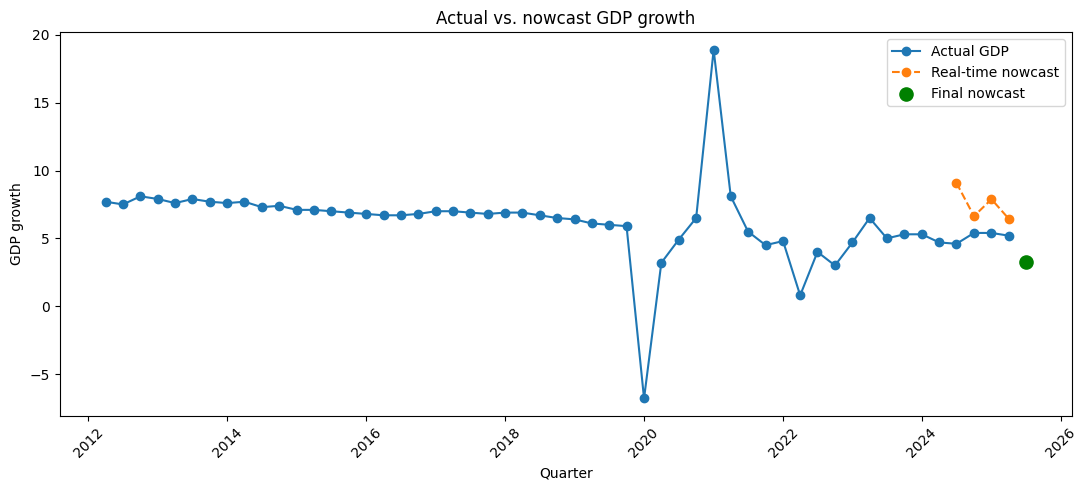

In [28]:
plt.figure(figsize=(11, 5))
plt.plot(known['index'], known['GDP'], marker='o', label='Actual GDP')
plt.plot(realtime_results['index'], realtime_results['realtime_nowcast'],
         marker='o', linestyle='--', label='Real-time nowcast')
plt.scatter(to_nowcast['index'], to_nowcast['nowcast'],
            color='green', s=90, label='Final nowcast')
plt.xlabel('Quarter')
plt.ylabel('GDP growth')
plt.title('Actual vs. nowcast GDP growth')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 8. Historical fit visualization

> ⚠️ **In-sample fit:** Use this plot for visualization only, not for evaluating predictive performance.

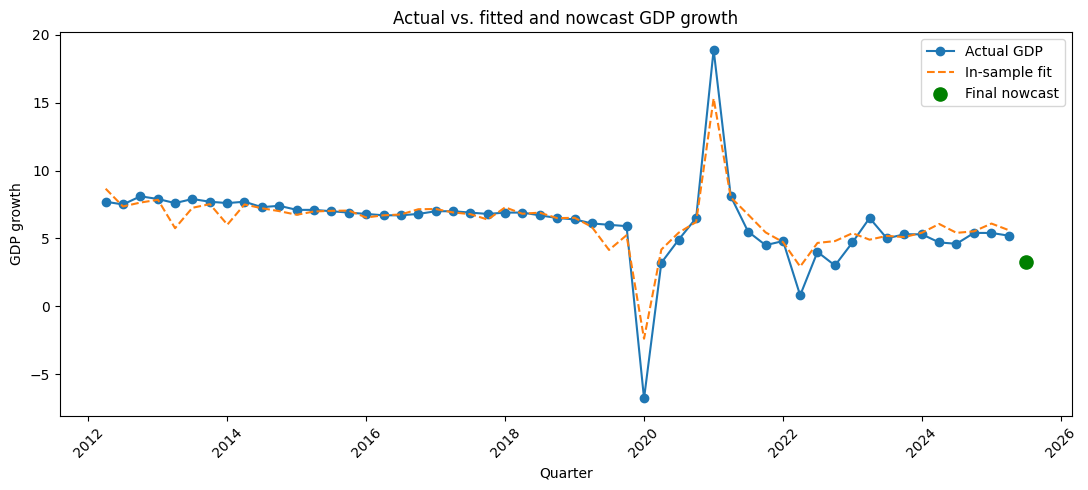

In [29]:
known_fit = known.copy()
known_fit['fitted'] = model_final.predict(known_fit[feature_cols])

plt.figure(figsize=(11, 5))
plt.plot(known_fit['index'], known_fit['GDP'], marker='o', label='Actual GDP')
plt.plot(known_fit['index'], known_fit['fitted'], linestyle='--', label='In-sample fit')
plt.scatter(to_nowcast['index'], to_nowcast['nowcast'],
            color='green', s=90, label='Final nowcast')
plt.xlabel('Quarter')
plt.ylabel('GDP growth')
plt.title('Actual vs. fitted and nowcast GDP growth')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 9. Save outputs

In [ ]:
output_path = os.path.join(ROOT, 'output')
os.makedirs(output_path, exist_ok=True)

realtime_results.to_csv(
    os.path.join(output_path, 'gdp_realtime_test_results.csv'), index=False
)
to_nowcast[['index', 'nowcast']].to_csv(
    os.path.join(output_path, 'gdp_final_nowcast.csv'), index=False
)


with open('gdp_nowcast_model.pkl', 'wb') as f:
    pickle.dump(model_final, f)

with open('gdp_nowcast_model.pkl', 'rb') as f:
    model_final = pickle.load(f)